# Structures, thermal, and separation

Start with the trajectory's load cases, then explore a tank-thickness trade.
Keep loads from the **same instant** together; independent maxima do not
describe a real flight condition.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from hyperion.workspace import current_flight
from hyperion.structures import tank_stress
from hyperion.verification import input_contracts

%matplotlib inline


## 1. Get the flight loads

Use these cases to define structural loading. Forces and moments are
rigid-body results; flexibility and vibration need a structural model.


In [2]:
flight, summary, model = current_flight()
columns = {
    "case": "Load case",
    "t_s": "Time (s)",
    "mass_kg": "Vehicle mass (kg)",
    "normal_force_N": "Normal force (N)",
    "aero_moment_Nm": "Aero moment (N·m)",
    "payload_axial_force_N": "Payload axial force (N)",
    "payload_lateral_force_N": "Payload lateral force (N)",
}
display(model.load_cases[list(columns)].rename(columns=columns).round(2))


,Load case,Time (s),Vehicle mass (kg),Normal force (N),Aero moment (N·m),Payload axial force (N),Payload lateral force (N)
0,Max-Q,63.40,409096.85,4398.16,154552.78,57030.29,164.86
1,Max-Qalpha,46.60,437794.11,25361.58,892656.53,60892.48,456.07
2,Max axial acceleration,217.76,121234.61,411.12,6382.99,240597.63,24.97
3,Max lateral acceleration,220.96,79947.16,525.02,2512.08,47946.66,756.54
4,Max aerodynamic moment,46.60,437794.11,25361.58,892656.53,60892.48,456.07
5,Max TVC demand,46.60,437794.11,25361.58,892656.53,60892.48,456.07
6,Max thrust,0.00,528757.07,144.26,5054.53,55178.85,12.62
7,Max aerodynamic normal force,46.60,437794.11,25361.58,892656.53,60892.48,456.07
8,Max aerodynamic axial force,76.40,388581.98,2050.98,70742.61,58256.42,64.26


## 2. Compare tank thicknesses

This reproduces the source's **1–6 mm** pressure-only cylindrical tank trade
using **87.022608 psi**, a **2.7 m radius**, and **43 ksi** Al2219 yield strength.
A utilization below 1 passes this calculation's yield check only.

Inputs come from `Structures Sizing.xlsx`, `Tank Sizing!B3:D8` and
`Material Properties!B3:H3`. The yield factor **1.25** comes from `STR.3.SYS.03`;
the separate ultimate factor is **1.40**. Some source stress-ratio formulas
have broken references, so this calculation recomputes them.


,Thickness (mm),Yield utilization
0,1,5.915
1,2,2.958
2,3,1.972
3,4,1.479
4,5,1.183
5,6,0.986


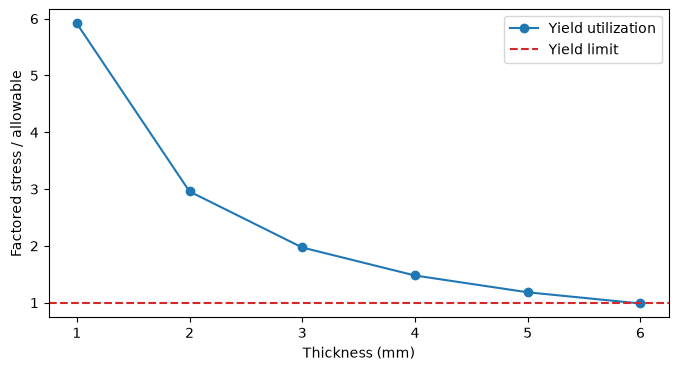

In [3]:
PSI_TO_PA = 6894.757293168
PRESSURE_PA = 87.0226084737 * PSI_TO_PA
RADIUS_M = 2.7
YIELD_STRENGTH_PA = 43_000 * PSI_TO_PA
YIELD_FACTOR = 1.25
THICKNESSES_MM = [1, 2, 3, 4, 5, 6]

rows = []
for thickness_mm in THICKNESSES_MM:
    result = tank_stress(
        radius_m=RADIUS_M,
        thickness_m=thickness_mm / 1000,
        pressure_pa=PRESSURE_PA,
        axial_force_n=0,
        bending_moment_nm=0,
        torque_nm=0,
        yield_allowable_pa=YIELD_STRENGTH_PA,
        joint_efficiency=1,
        load_factor=YIELD_FACTOR,
    )
    rows.append(
        {
            "Thickness (mm)": thickness_mm,
            "Yield utilization": result["yield"]["utilization"],
        }
    )

trade = pd.DataFrame(rows)
display(trade.round(3))
axis = trade.plot(x="Thickness (mm)", y="Yield utilization", marker="o", figsize=(8, 4))
axis.axhline(1, color="tab:red", linestyle="--", label="Yield limit")
axis.set_ylabel("Factored stress / allowable")
axis.legend()
plt.show()


## 3. Choose the next analysis

The installed tank still needs weld, opening, thermal, buckling, and combined
flight-load checks. Structural and thermal solvers need documented geometry,
materials, boundary conditions, and model matrices.

Change the function below to `modal`, `thermal_network`, or
`deformation_clearance` to see its inputs. The full list is in
[calculation_inputs.csv](data/calculation_inputs.csv).
Separation clearance also needs release states, dimensions, and dispersions;
the ascent's separation impulse alone does not establish no recontact.


In [4]:
CALCULATION = "tank_stress"
calculations = input_contracts().set_index("calculation")
selected = calculations.loc[CALCULATION]
print(selected["description"])
display(pd.DataFrame({"Required input": selected["required_inputs"].split(", ")}))


Thin closed-end cylinder membrane plus axial bending; extrema at both fibers.


,Required input
0,radius_m
1,thickness_m
2,pressure_pa
3,axial_force_n
4,bending_moment_nm
5,torque_nm
6,yield_allowable_pa
7,joint_efficiency
8,load_factor
